# Possession and pass-event detection

**Analytical question:** Recover candidate on-ball events.

**Stages in this notebook:** Player–ball vectors; ball kinematics; sustained proximity and low-speed possession; release/transit/reception; timing evaluation.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports and data location

## Reading the code

Each statement performs one step. Names describe the values being calculated, and comments explain the purpose or units. A `for` loop repeats the indented steps for each player, frame or example. A function groups steps that we reuse later.

`pandas` tables hold the data. Square brackets select columns or rows; a condition such as `distance < 2` creates a True/False filter. `NumPy` arrays hold numbers for the calculations. `axis=0` refers to rows and `axis=1` to columns in a two-dimensional array. Shape comments explain additional dimensions where needed.

Run the worked calculations in order before using the final exploration section. The plotting and file-loading functions are included here so the notebook runs on its own.

Use `and` to combine individual True/False values. Use `&` to combine whole pandas columns of conditions. `np.hypot(dx, dy)` calculates distance from horizontal and vertical differences. `np.column_stack` joins columns, while `np.concatenate` joins existing arrays.

In [1]:
from pathlib import Path
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT_items_1 = []
for p in candidates:
    if (p / "data/1925299/1925299_match.json").exists():
        ROOT_items_1.append(p)
if len(ROOT_items_1) > 0:
    ROOT = ROOT_items_1[0]
else:
    ROOT = Path.cwd()
DATA_ROOT = ROOT / "data/1925299"


## Choose an example with selection variables

First run the notebook top to bottom. For another example, change these variables, run this selection cell, then rerun the final exploration cell. Refit models only when you intend to. Near the end, `available_possessions` and `available_events` list available choices; use their displayed identifiers. You can inspect more rows with `display(available_possessions)` or `display(available_events)`. A frame override takes priority over a possession or event. Method-specific selectors are documented in the comments.

The final explorer computes its overlays directly from real tracking frames and the method functions in this notebook. Animation frames are rendered inline using Matplotlib; no MP4 or other movie is downloaded. Missing coverage stops the clip rather than interpolating motion. The saved notebook contains a playable default animation, but choosing another example requires rerunning Python. All helpers remain inline.

In [2]:
# Example selection: change a selection, then rerun the cells below. None uses the worked default.
PERIOD = 1
FRAME_ID = None  # exact raw tracking frame; overrides event/possession start
POSSESSION_INDEX = None  # possession_index from available_possessions near the end
EVENT_ID = None  # actual supplied event_id from available_events, not row number
PLAYER_ID = None  # player_id (string or integer), from metadata
TEAM_ID = None  # team_id; None uses the initial possession team
DURATION_S = 6.0  # maximum; clips stop at coverage/selection boundaries
FRAME_STRIDE = 3  # use 1 for every 10 Hz frame; 3 gives a faster preview
PASS_INDEX = 0  # row number in detected passes, shown near the end


## 2. Inline ingestion and plotting helpers

In [3]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True, exist_ok=True)
    revision = "4340d274572876239c154c90bc507a9b3250a656"
    base = f"https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/"
    for suffix in ["match.json", "dynamic_events.csv", "phases_of_play.csv"]:
        name = "1925299_" + suffix
        target = destination / name
        if not target.exists():
            with urllib.request.urlopen(base + name, timeout=90) as response:
                target.write_bytes(response.read())
    name = "1925299_tracking_extrapolated.jsonl"
    target = destination / name
    if not target.exists():
        url = (
            base.replace(
                "raw.githubusercontent.com/", "media.githubusercontent.com/media/"
            )
            + name
        )
        temporary = destination / (name + ".partial")
        with urllib.request.urlopen(url, timeout=90) as response, temporary.open(
            "wb"
        ) as output:
            count = 0
            for line in response:
                if line.strip():
                    json.loads(line)
                    output.write(line)
                    count += 1
                if count >= 9000:
                    break
        temporary.replace(target)


def read_tracking(destination):
    """Load the sample and make one table row for each player in each frame."""
    dataset = skillcorner.load(
        meta_data=destination / "1925299_match.json",
        raw_data=destination / "1925299_tracking_extrapolated.jsonl",
        coordinates="skillcorner",
    )
    wide = dataset.to_df()
    metadata_file = destination / "1925299_match.json"
    metadata = json.loads(metadata_file.read_text(encoding="utf-8"))

    # Each line in the tracking file is one JSON record.
    raw_records = []
    tracking_file = destination / "1925299_tracking_extrapolated.jsonl"
    for line in tracking_file.read_text().splitlines():
        if line.strip():
            raw_records.append(json.loads(line))

    # Dictionaries let us look up a value using a frame or player identifier.
    player_possession = {}
    visibility = {}
    for record in raw_records:
        frame_number = record["frame"]
        possession = record.get("possession", {})
        (player_possession[frame_number]) = str(possession.get("player_id"))
        for player in record.get("player_data", []):
            player_id = str(player["player_id"])
            (visibility[frame_number, player_id]) = player.get("is_detected")

    player_tables = []
    for player in metadata["players"]:
        player_id = str(player["id"])
        x_column = player_id + "_x"
        y_column = player_id + "_y"
        if x_column not in wide.columns:
            continue
        columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "ball_owning_team_id",
            x_column,
            y_column,
        ]
        player_table = wide[columns].copy()
        player_table.columns = [
            "period_id",
            "frame_id",
            "timestamp",
            "team_in_possession",
            "x",
            "y",
        ]
        (player_table["player_id"]) = player_id
        (player_table["team_id"]) = player["team_id"]
        (player_table["name"]) = player["short_name"]
        player_tables.append(player_table)

    tracking = pd.concat(player_tables, ignore_index=True)
    (tracking["seconds"]) = tracking["timestamp"].dt.total_seconds()
    (tracking["player_in_possession"]) = tracking["frame_id"].map(player_possession)
    detection_flags = []
    for row in tracking.itertuples():
        detection_flags.append(visibility.get((row.frame_id, row.player_id)))
    (tracking["is_detected"]) = detection_flags
    tracking = tracking.sort_values(["player_id", "period_id", "frame_id"])
    return dataset, wide, tracking, metadata, raw_records


def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5.5))
    ax.set_facecolor("#eef3ed")
    ax.add_patch(Rectangle((-52.5, -34), 105, 68, fill=False, color="#597063"))
    ax.plot([0, 0], [-34, 34], c="#597063")
    ax.add_patch(Circle((0, 0), 9.15, fill=False, color="#597063"))
    for x in [-52.5, 36]:
        ax.add_patch(Rectangle((x, -20.16), 16.5, 40.32, fill=False, color="#597063"))
    ax.set(
        xlim=(-55, 55), ylim=(-36, 36), aspect="equal", xlabel="x (m)", ylabel="y (m)"
    )
    return ax


## 3. Read the real sample

In [4]:
ensure_sample(DATA_ROOT)
dataset, wide, tracking, metadata, raw = read_tracking(DATA_ROOT)
events = pd.read_csv(DATA_ROOT / "1925299_dynamic_events.csv")
phases = pd.read_csv(DATA_ROOT / "1925299_phases_of_play.csv")
observed = tracking.dropna(subset=["x", "y"])
complete = observed.groupby(["period_id", "frame_id"]).size()
if FRAME_ID is not None:
    frame_id = int(FRAME_ID)
else:
    frame_id = int(complete[complete == 22].index[20][1])
snapshot = observed[observed.frame_id == frame_id].copy()
keepers = set()
for p in metadata["players"]:
    if "goalkeeper" in p["player_role"]["name"].lower():
        keepers.add(str(p["id"]))
role_labels = {}
for p in metadata["players"]:
    (role_labels[str(p["id"])]) = p["player_role"]["acronym"]
assert not tracking.duplicated(["period_id", "frame_id", "player_id"]).any()
display(
    tracking[["period_id", "frame_id", "player_id", "x", "y", "is_detected"]].head(3)
)
print("Real bounded sample. Diagnostic frame:", frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Calculate player–ball vectors

Inspect coordinate differences for one frame before calculating possession candidates.

,player,dx,dy,distance_m
6174,966112,2.08,1.55,2.594012
98469,287934,4.36,1.15,4.509113
36939,51002,-5.44,-2.23,5.879328
21,51050,7.62,-3.19,8.260781
30786,560986,-3.24,-8.02,8.649740
55398,560984,-3.09,-8.20,8.762882
43092,560882,-8.46,5.84,10.279942
116928,965697,10.33,4.86,11.416151


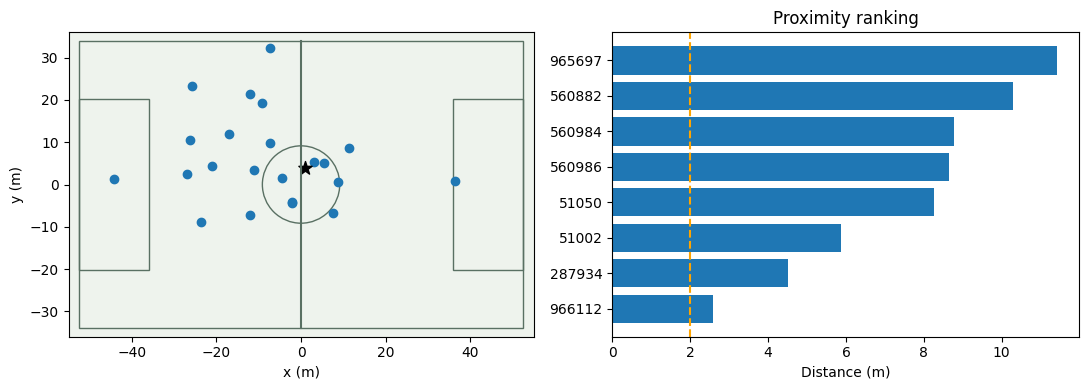

In [5]:
def player_ball_vectors(players, ball_xy):
    return players[["x", "y"]].to_numpy() - np.asarray(ball_xy)


def vector_lengths(vectors):
    return np.sqrt((vectors**2).sum(axis=1))


ball_row = wide[wide.frame_id == frame_id].iloc[0]
ball_xy = np.array([ball_row.ball_x, ball_row.ball_y])
players = snapshot.copy()
vectors = player_ball_vectors(players, ball_xy)
(players["distance_m"]) = vector_lengths(vectors)
display(
    pd.DataFrame(
        {
            "player": players.player_id,
            "dx": vectors[:, 0],
            "dy": vectors[:, 1],
            "distance_m": players.distance_m,
        }
    )
    .sort_values("distance_m")
    .head(8)
)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
pitch(axs[0])
axs[0].scatter(players.x, players.y)
axs[0].scatter(*ball_xy, marker="*", c="black", s=100)
rank = players.nsmallest(8, "distance_m")
axs[1].barh(rank.player_id, rank.distance_m)
axs[1].axvline(2, c="orange", ls="--")
axs[1].set(xlabel="Distance (m)", title="Proximity ranking")
plt.tight_layout()
plt.show()


## 5. Derive ball motion and create control candidates

Differentiate coordinates before applying rules: velocity is displacement divided by elapsed time, speed is the length of that velocity vector, and acceleration is change in velocity divided by elapsed time. Compute within a period and only across adjacent frames with valid timestamps. Differentiation amplifies coordinate noise; these unsmoothed diagnostics are teaching measurements.

Our conservative control rule requires **distance ≤2 m, ball height 0–2 m, horizontal ball speed ≤3 m/s**, for the **same nearest player over ≥0.3 s**. Proximity alone can label an overhead ball or a dummy as a touch. The height/speed gates and persistence reduce these cases but cannot establish deliberate control. These thresholds are assumptions, not fitted or provider definitions.

,frame_id,player_id,distance,ball_z,ball_speed_mps,candidate
24603,40,51002,0.909340,0.30,NaN,NaN
24604,41,51002,1.387083,0.28,4.601087,NaN
24605,42,51002,2.025562,0.26,6.000833,NaN
24606,43,51002,2.745269,0.24,6.600758,NaN
24607,44,51002,3.503655,0.22,6.800735,NaN
24608,45,51002,4.243018,0.22,6.500769,NaN
24609,46,51002,4.922286,0.21,5.603570,NaN
24610,47,51002,5.563596,0.19,5.115662,NaN
24611,48,51002,6.237219,0.18,5.162364,NaN
6162,49,287934,6.288283,0.16,4.825971,NaN


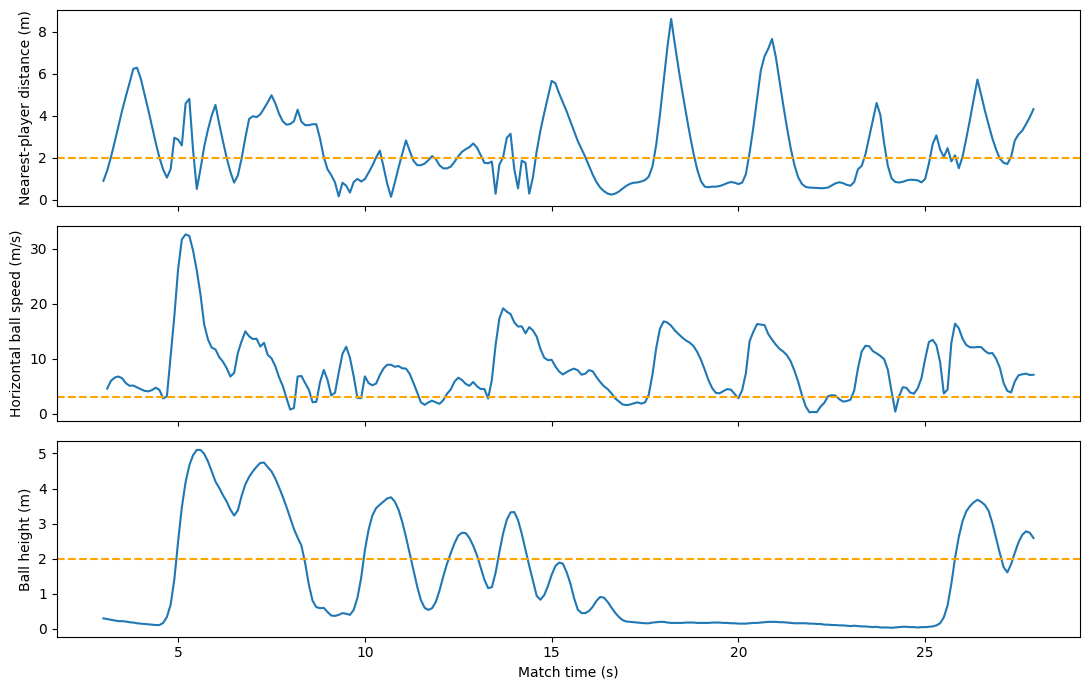

In [6]:
def ball_kinematics(path):
    """Backward finite differences, without crossing periods, gaps or missing data."""
    path = path.sort_values(["period_id", "frame_id"]).copy()
    groups = path.groupby("period_id", sort=False)
    (path["seconds"]) = path.timestamp.dt.total_seconds()
    (path["dt"]) = groups.seconds.diff()
    adjacent = (groups.frame_id.diff() == 1) & path.dt.between(0.05, 0.15)
    (path["vx"]) = (groups.ball_x.diff() / path.dt).where(adjacent)
    (path["vy"]) = (groups.ball_y.diff() / path.dt).where(adjacent)
    (path["ball_speed_mps"]) = np.hypot(path.vx, path.vy)
    (path["step_m"]) = np.hypot(groups.ball_x.diff(), groups.ball_y.diff()).where(
        adjacent
    )
    (path["ax"]) = (path.groupby("period_id").vx.diff() / path.dt).where(adjacent)
    (path["ay"]) = (path.groupby("period_id").vy.diff() / path.dt).where(adjacent)
    (path["acceleration_mps2"]) = np.hypot(path.ax, path.ay)
    return path


def control_gate(frame, distance_m=2.0, max_height_m=2.0, max_speed_mps=3.0):
    """A frame qualifies only when all three physical conditions are true."""
    close_to_player = frame["distance"] <= distance_m
    low_ball = frame["ball_z"].between(0, max_height_m)
    slow_ball = frame["ball_speed_mps"].between(0, max_speed_mps)
    return close_to_player & low_ball & slow_ball


ball_motion = ball_kinematics(wide)
joined = observed.merge(
    ball_motion[
        ["period_id", "frame_id", "ball_x", "ball_y", "ball_z", "ball_speed_mps"]
    ],
    on=["period_id", "frame_id"],
    validate="many_to_one",
)
(joined["distance"]) = np.hypot(joined.x - joined.ball_x, joined.y - joined.ball_y)
valid = joined.dropna(subset=["distance"])
nearest = (
    valid.loc[valid.groupby(["period_id", "frame_id"]).distance.idxmin()]
    .sort_values(["period_id", "frame_id"])
    .copy()
)
(nearest["proximity_only"]) = nearest.player_id.where(nearest.distance <= 2)
(nearest["candidate"]) = nearest.player_id.where(control_gate(nearest))
display(
    nearest[
        ["frame_id", "player_id", "distance", "ball_z", "ball_speed_mps", "candidate"]
    ].head(12)
)
fig, axs = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
example = nearest.head(250)
for ax, column, cutoff, title in zip(
    axs,
    ["distance", "ball_speed_mps", "ball_z"],
    [2, 3, 2],
    ["Nearest-player distance (m)", "Horizontal ball speed (m/s)", "Ball height (m)"],
):
    ax.plot(example.seconds, example[column])
    ax.axhline(cutoff, c="orange", ls="--")
    ax.set_ylabel(title)
axs[-1].set_xlabel("Match time (s)")
plt.tight_layout()
plt.show()
# Rule checks: nearby slow ball qualifies, fast dummy and high flyover do not.
checks = pd.DataFrame(
    {
        "distance": [1, 1, 1, 3, 1],
        "ball_z": [0.2, 0.2, 3, 0.2, 0.2],
        "ball_speed_mps": [1, 9, 1, 1, np.nan],
    }
)
assert control_gate(checks).tolist() == [True, False, False, False, False]
# No motion estimate can bridge a missing frame or a new period.
fixture = pd.DataFrame(
    {
        "period_id": [1, 1, 1, 2],
        "frame_id": [0, 1, 3, 4],
        "timestamp": pd.to_timedelta([0, 0.1, 0.3, 0.4], unit="s"),
        "ball_x": [0, 0.2, 0.6, 0.8],
        "ball_y": [0, 0, 0, 0],
    }
)
assert np.allclose(ball_kinematics(fixture).ball_speed_mps.iloc[1], 2.0)
assert ball_kinematics(fixture).ball_speed_mps.iloc[[0, 2, 3]].isna().all()


## 6. Group stable possession intervals

Only after seeing frame candidates do we merge consecutive identical labels. Gaps and period changes start new segments. All proximity, speed and height gates must hold for every frame in a stable interval. At native 10 Hz, three consecutive qualifying samples represent a 0.3 s sample interval. Labels are assigned retrospectively; online confirmation would have a delay.

In [7]:
(nearest["break"]) = (
    (nearest.period_id != nearest.period_id.shift())
    | (nearest.frame_id.diff() != 1)
    | (nearest.candidate != nearest.candidate.shift())
)
(nearest["segment"]) = nearest["break"].cumsum()
segments = nearest.groupby("segment").agg(
    period=("period_id", "first"),
    start=("frame_id", "min"),
    end=("frame_id", "max"),
    player=("candidate", "first"),
    team=("team_id", "first"),
    frames=("frame_id", "size"),
)
(segments["duration_s"]) = segments.frames / 10
stable = segments[segments.player.notna() & (segments.duration_s >= 0.3)].copy()
display(stable.head(12))


,period,start,end,player,team,frames,duration_s
segment,,,,,,,
85,1,125,127,560989,871,3,0.3
87,1,129,131,560882,1802,3,0.3
133,1,177,185,965697,1802,9,0.9
176,1,228,233,560983,1802,6,0.6
180,1,237,240,560983,1802,4,0.4
317,1,378,384,795530,871,7,0.7
455,1,522,528,11897,871,7,0.7
456,1,529,534,560984,871,6,0.6
499,1,577,585,51050,1802,9,0.9


## 7. Inspect ball travel before identifying passes

Introduce the ball-path helper and inspect displacement and speed on a continuous sample. This is the evidence used in the next step.

,frame_id,dt,step_m,ball_speed_mps
0,40,NaN,NaN,NaN
1,41,0.1,0.460109,4.601087
2,42,0.1,0.600083,6.000833
3,43,0.1,0.660076,6.600758
4,44,0.1,0.680074,6.800735
5,45,0.1,0.650077,6.500769
6,46,0.1,0.560357,5.603570
7,47,0.1,0.511566,5.115662
8,48,0.1,0.516236,5.162364
9,49,0.1,0.482597,4.825971


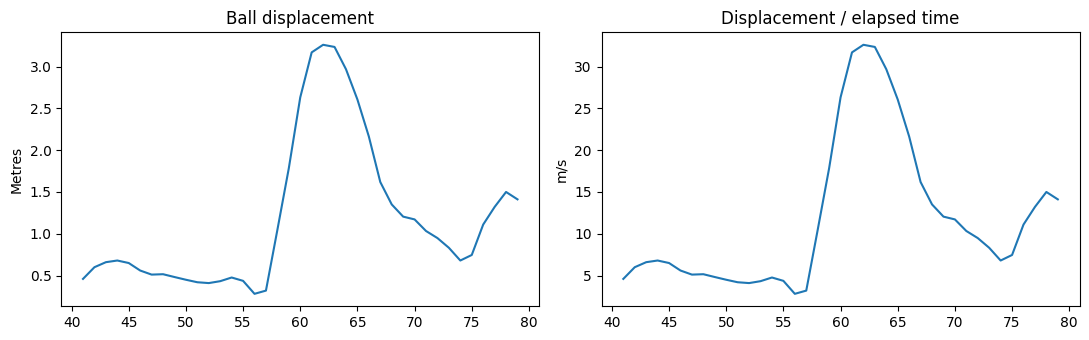

In [8]:
def ball_path_steps(path):
    return ball_kinematics(path)


path = ball_path_steps(wide.head(40))
display(path[["frame_id", "dt", "step_m", "ball_speed_mps"]].head(10))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(path.frame_id, path.step_m)
axs[0].set(title="Ball displacement", ylabel="Metres")
axs[1].plot(path.frame_id, path.ball_speed_mps)
axs[1].set(title="Displacement / elapsed time", ylabel="m/s")
plt.tight_layout()
plt.show()


## 8. Final detection output: pass candidates

Pair stable same-team possessions only when the intervening ball path is covered and moves at least three metres.

,period,release,reception,passer,receiver,displacement_m
0,1,1464,1476,966114,50982,8.766807
1,1,1782,1796,287934,51043,12.536415
2,1,1803,1834,51043,965697,13.604830
3,1,2299,2323,560985,809166,13.175508
4,1,2697,2725,51043,797298,17.224750
5,1,2810,2849,51050,287934,18.074925
6,1,2855,2871,287934,965697,16.150028
7,1,3767,3790,51043,560882,15.827751
8,1,3840,3853,560882,51043,6.060825
9,1,3901,3927,51043,965697,14.832754


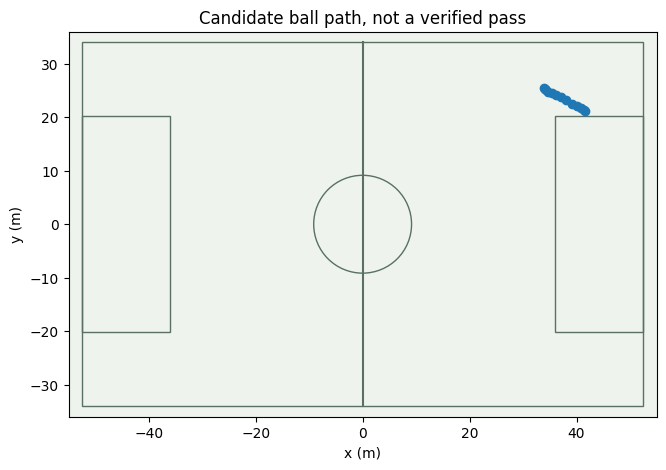

In [9]:
def detect_pass_candidates(stable, wide):
    """Link two same-team control intervals when the ball travels between them."""
    candidates = []
    possession_rows = list(stable.itertuples())
    for index in range(len(possession_rows) - 1):
        passer = possession_rows[index]
        receiver = possession_rows[index + 1]
        same_period = passer.period == receiver.period
        same_team = passer.team == receiver.team
        different_players = passer.player != receiver.player
        if not (same_period and same_team and different_players):
            continue

        gap_frames = receiver.start - passer.end
        in_period = wide["period_id"] == passer.period
        between_endpoints = wide["frame_id"].between(passer.end, receiver.start)
        ball_path = ball_path_steps(wide[in_period & between_endpoints])
        complete_path = len(ball_path) == gap_frames + 1
        missing_positions = ball_path[["ball_x", "ball_y"]].isna().any().any()
        if not (1 <= gap_frames <= 40 and complete_path) or missing_positions:
            continue

        start_position = ball_path[["ball_x", "ball_y"]].iloc[0].to_numpy()
        end_position = ball_path[["ball_x", "ball_y"]].iloc[-1].to_numpy()
        displacement_m = np.linalg.norm(end_position - start_position)
        if displacement_m >= 3:
            candidates.append(
                {
                    "period": passer.period,
                    "release": passer.end,
                    "reception": receiver.start,
                    "passer": passer.player,
                    "receiver": receiver.player,
                    "displacement_m": displacement_m,
                }
            )
    columns = ["period", "release", "reception", "passer", "receiver", "displacement_m"]
    return pd.DataFrame(candidates, columns=columns)


passes = detect_pass_candidates(stable, wide)
display(passes.head(10))
fig, ax = plt.subplots(figsize=(9, 5))
pitch(ax)
if len(passes):
    p = passes.iloc[0]
    path = wide[
        (wide.period_id == p.period) & wide.frame_id.between(p.release, p.reception)
    ]
    ax.plot(path.ball_x, path.ball_y, "o-")
ax.set_title("Candidate ball path, not a verified pass")
plt.show()


## 9. Evaluate timing with one-to-one matching

Evaluation follows detection. This synthetic check illustrates tolerance sensitivity; it is not a measured accuracy result.

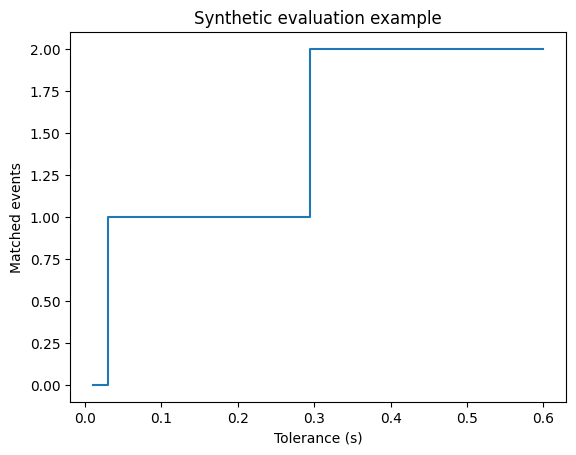

In [10]:
from scipy.optimize import linear_sum_assignment


def timing_scores(predicted, truth, tolerance_s=0.5):
    predicted = np.asarray(predicted)
    truth = np.asarray(truth)
    if not len(predicted) or not len(truth):
        return {"tp": 0, "fp": len(predicted), "fn": len(truth)}
    delta = np.abs(predicted[:, None] - truth[None, :])
    # A large penalty first maximizes the count of eligible one-to-one matches.
    cost = np.where(delta <= tolerance_s, delta, 1e6)
    rows, cols = linear_sum_assignment(cost)
    tp = int((delta[rows, cols] <= tolerance_s).sum())
    return {"tp": tp, "fp": len(predicted) - tp, "fn": len(truth) - tp}


assert timing_scores([1, 1.1], [1], 0.2) == {"tp": 1, "fp": 1, "fn": 0}
tolerances = np.linspace(0.01, 0.6, 30)
counts = []
for t in tolerances:
    counts.append(timing_scores([1.0, 1.1, 3.3], [1.05, 3.0, 5.0], t)["tp"])
plt.step(tolerances, counts)
plt.xlabel("Tolerance (s)")
plt.ylabel("Matched events")
plt.title("Synthetic evaluation example")
plt.show()


## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,possession_index,period,start_frame,end_frame,team_id,duration_s
0,0,1,10,39,NaN,3.0
1,1,1,40,306,1802.0,26.7
2,2,1,307,347,871.0,4.1
3,3,1,348,371,1802.0,2.4
4,4,1,372,573,871.0,20.2
5,5,1,574,586,1802.0,1.3
6,6,1,587,592,NaN,0.6
7,7,1,593,598,871.0,0.6
8,8,1,599,784,NaN,18.6
9,9,1,973,987,871.0,1.5


,event_id,event_type,frame_start,frame_end
0,8_0,player_possession,39,39
1,1_0,off_ball_run,43,67
2,8_1,player_possession,57,57
3,7_0,passing_option,57,57
4,8_2,player_possession,89,94
5,7_1,passing_option,89,94
6,7_2,passing_option,91,94
7,9_0,on_ball_engagement,134,143
8,9_1,on_ball_engagement,135,143
9,8_3,player_possession,143,143


,pass_index,period,release,reception,passer,receiver,displacement_m
0,0,1,1464,1476,966114,50982,8.766807
1,1,1,1782,1796,287934,51043,12.536415
2,2,1,1803,1834,51043,965697,13.604830
3,3,1,2299,2323,560985,809166,13.175508
4,4,1,2697,2725,51043,797298,17.224750
5,5,1,2810,2849,51050,287934,18.074925
6,6,1,2855,2871,287934,965697,16.150028
7,7,1,3767,3790,51043,560882,15.827751
8,8,1,3840,3853,560882,51043,6.060825
9,9,1,3901,3927,51043,965697,14.832754


Recomputed overlays on 11 real frames; first/last: (1, 1456) (1, 1486)


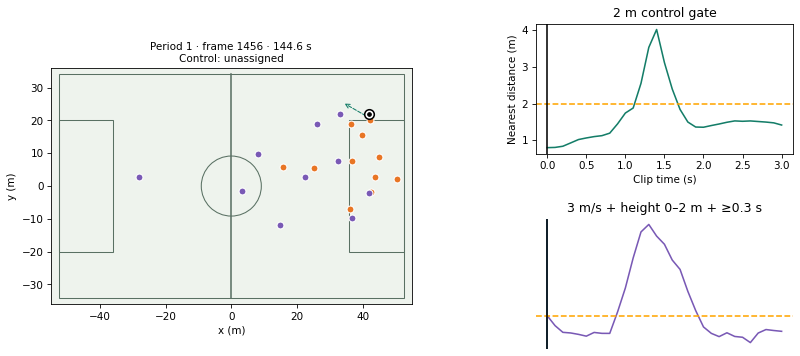

In [11]:
method_name = "events"
# All animation inputs and method calculations are local tracking data, not a video asset.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon, Wedge
from IPython.display import HTML, display

players_by_id = {}
for player in metadata["players"]:
    (players_by_id[str(player["id"])]) = player
home_team_id = int(metadata["home_team"]["id"])
away_team_id = int(metadata["away_team"]["id"])
tracking_records = list(raw)
if method_name == "graph_epv":
    unique_records_by_key = {}
    for record in raw + goal_sequence:
        if record.get("period") is not None:
            (unique_records_by_key[int(record["period"]), int(record["frame"])]) = (
                record
            )
    tracking_records = list(unique_records_by_key.values())
source_frames = {}
for record in tracking_records:
    if record.get("period") is not None:
        (source_frames[int(record["period"]), int(record["frame"])]) = record
frames_by_key = {}
for frame_key, record in source_frames.items():
    position_flags = []
    for player in record["player_data"]:
        position_flags.append(
            player.get("x") is not None and player.get("y") is not None
        )
    if (
        frame_key[0] == PERIOD
        and len(record.get("player_data", [])) == 22
        and all(position_flags)
        and (record.get("ball_data", {}).get("x") is not None)
        and (record["ball_data"].get("y") is not None)
        and (record.get("timestamp") is not None)
    ):
        (frames_by_key[frame_key]) = record
assert frames_by_key, "No complete frames for PERIOD in the cached source."


def tracking_time(record):
    return pd.to_timedelta(record["timestamp"]).total_seconds()


def possession_team(record):
    """Translate the source's team label into the corresponding team identifier."""
    group = record.get("possession", {}).get("group")
    if group == "home team":
        return home_team_id
    if group == "away team":
        return away_team_id
    return None


def attack_direction(team, period):
    """Return -1 for attacks to the left and +1 for attacks to the right."""
    home_attacks_left = metadata["home_team_side"][period - 1] == "right_to_left"
    if team == home_team_id:
        attacks_left = home_attacks_left
    else:
        attacks_left = not home_attacks_left
    if attacks_left:
        return -1
    return 1


def players_at_frame(frame_key):
    """Make a player table and estimate velocity using the immediately previous frame."""
    record = frames_by_key[frame_key]
    period, frame_number = frame_key
    previous_record = source_frames.get((period, frame_number - 1))
    previous_players = {}
    elapsed_seconds = np.nan
    if previous_record is not None:
        for player in previous_record.get("player_data", []):
            (previous_players[str(player["player_id"])]) = player
        if previous_record.get("timestamp"):
            elapsed_seconds = tracking_time(record) - tracking_time(previous_record)

    player_rows = []
    for player in record["player_data"]:
        player_id = str(player["player_id"])
        previous_player = previous_players.get(player_id, {})
        velocity = np.array([np.nan, np.nan])
        valid_time = 0.05 <= elapsed_seconds <= 0.15
        has_previous_x = previous_player.get("x") is not None
        has_previous_y = previous_player.get("y") is not None
        if valid_time and has_previous_x and has_previous_y:
            current_position = np.array([player["x"], player["y"]])
            previous_position = np.array([previous_player["x"], previous_player["y"]])
            velocity = (current_position - previous_position) / elapsed_seconds
        player_rows.append(
            {
                "player_id": player_id,
                "team_id": int(players_by_id[player_id]["team_id"]),
                "x": player["x"],
                "y": player["y"],
                "vx": velocity[0],
                "vy": velocity[1],
                "is_detected": player.get("is_detected"),
            }
        )
    return pd.DataFrame(player_rows)


def draw_tracking_frame(axis, frame_key):
    tracking_record = frames_by_key[frame_key]
    player_table = players_at_frame(frame_key)
    pitch(axis)
    for team_id, color in [(home_team_id, "#e87524"), (away_team_id, "#7959b5")]:
        team_players = player_table[player_table.team_id == team_id]
        axis.scatter(
            team_players.x, team_players.y, c=color, edgecolors="white", s=44, zorder=5
        )
    ball_position = np.array(
        [tracking_record["ball_data"]["x"], tracking_record["ball_data"]["y"]]
    )
    axis.scatter(*ball_position, s=85, c="white", edgecolors="black", lw=1.5, zorder=10)
    axis.scatter(*ball_position, s=12, c="black", zorder=11)
    axis.set_title(
        f"Period {frame_key[0]} · frame {frame_key[1]} · {tracking_time(tracking_record):.1f} s",
        fontsize=11,
    )
    return player_table, ball_position, tracking_record


# Possessions here are uninterrupted supplied team-possession spans, not inferred player control.
example_catalog = []
previous = None
group = None
for frame_key in sorted(frames_by_key):
    record = frames_by_key[frame_key]
    current_possession_team = possession_team(record)
    continuous = (
        previous is not None
        and frame_key[1] == previous[1] + 1
        and 0 < tracking_time(record) - tracking_time(frames_by_key[previous]) <= 0.15
    )
    if not continuous or current_possession_team != group:
        example_catalog.append(
            dict(
                possession_index=len(example_catalog),
                period=frame_key[0],
                start_frame=frame_key[1],
                end_frame=frame_key[1],
                team_id=current_possession_team,
            )
        )
    else:
        (example_catalog[-1]["end_frame"]) = frame_key[1]
    previous = frame_key
    group = current_possession_team
available_possessions = pd.DataFrame(example_catalog)
(available_possessions["duration_s"]) = (
    available_possessions.end_frame - available_possessions.start_frame + 1
) / 10
if "events" in globals():
    available_events_items_1 = []
    for k in frames_by_key:
        available_events_items_1.append(k[1])
    available_events = events[
        (events.period == PERIOD) & events.frame_start.isin(available_events_items_1)
    ].copy()
else:
    available_events = pd.DataFrame()
display(available_possessions.head(10))
if len(available_events):
    display(
        available_events[["event_id", "event_type", "frame_start", "frame_end"]].head(
            10
        )
    )

clip_start_frame = None
clip_stop_frame = None
example_action = None
if method_name == "formation":
    available_windows = timeline[timeline.period == PERIOD].copy()
    display(available_windows.head(12))
    if FORMATION_WINDOW not in set(available_windows.window):
        raise ValueError(
            "FORMATION_WINDOW must be a qualifying window in available_windows."
        )
    example_window_data = team_data[
        (team_data.period_id == PERIOD)
        & (team_data.window == FORMATION_WINDOW)
        & (team_data.team_in_possession == 871)
    ]
    example_med = example_window_data.groupby("player_id")[["cx", "cy"]].median()
    example_points = -example_med.to_numpy()
    example_fits = []
    for name, t in templates.items():
        cost = ((example_points[:, None] - t[None]) ** 2).sum(2)
        rr, cc = linear_sum_assignment(cost)
        example_fits.append((name, float(np.sqrt(cost[rr, cc].mean())), cc))

    def assignment_error(fit):
        return fit[1]

    example_fits.sort(key=assignment_error)
    example_best = example_fits[0]
    candidates = []
    for k in frames_by_key:
        if (
            FORMATION_WINDOW * 30
            <= tracking_time(frames_by_key[k])
            < (FORMATION_WINDOW + 1) * 30
        ):
            candidates.append(k[1])
    assert candidates, "Selected formation window has no complete animation frames."
    clip_start_frame = min(candidates)
    clip_stop_frame = max(candidates)
elif method_name == "events":
    display(passes.reset_index(names="pass_index").head(12))
    if len(passes):
        assert 0 <= PASS_INDEX < len(passes), "PASS_INDEX is a row number in passes."
        example_action = passes.iloc[PASS_INDEX]
        clip_start_frame = max(int(example_action.release) - 8, 0)
        clip_stop_frame = int(example_action.reception) + 12
elif method_name == "xt":
    example_actions_items_1 = []
    for k in frames_by_key:
        example_actions_items_1.append(k[1])
    example_actions = (
        events[
            (events.event_type == "player_possession")
            & (events.end_type == "pass")
            & (events.pass_outcome == "successful")
            & (events.period == PERIOD)
            & events.frame_end.isin(example_actions_items_1)
        ]
        .dropna(
            subset=[
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        )
        .copy()
    )
    display(
        example_actions[
            [
                "event_id",
                "frame_end",
                "x_end",
                "y_end",
                "player_targeted_x_reception",
                "player_targeted_y_reception",
            ]
        ].head(12)
    )
    assert len(example_actions), "No completed actions with endpoint coverage."
    if EVENT_ID is None:
        example_action = example_actions.iloc[0]
    else:
        example_action = example_actions[example_actions.event_id == EVENT_ID].iloc[0]
    clip_start_frame = int(example_action.frame_end) - 5
elif method_name == "graph_epv" and SEQUENCE == "goal":
    clip_start_frame = int(goal_sequence[0]["frame"])
    clip_stop_frame = int(goal_sequence[-1]["frame"])
elif method_name == "graph_epv" and SEQUENCE == "non_goal":
    clip_start_frame = int(non_goal_sequence[0]["frame"])
    clip_stop_frame = int(non_goal_sequence[-1]["frame"])

if EVENT_ID is not None and method_name != "xt":
    chosen = available_events[available_events.event_id == EVENT_ID]
    assert (
        len(chosen) == 1
    ), "Choose EVENT_ID from available_events.event_id, not a row number."
    clip_start_frame = int(chosen.frame_start.iloc[0])
    clip_stop_frame = int(chosen.frame_end.iloc[0]) + 10
if POSSESSION_INDEX is not None:
    chosen = available_possessions[
        available_possessions.possession_index == POSSESSION_INDEX
    ]
    assert len(chosen) == 1, "Choose POSSESSION_INDEX from available_possessions."
    clip_start_frame = int(chosen.start_frame.iloc[0])
    clip_stop_frame = int(chosen.end_frame.iloc[0])
if FRAME_ID is not None:
    clip_start_frame = int(FRAME_ID)
    clip_stop_frame = None
if clip_start_frame is None:
    clip_start_frame = int(frame_id)
if (PERIOD, clip_start_frame) not in frames_by_key:
    # An event can start on a missing frame. Move forward only within its own interval.
    possible = []
    for k in sorted(frames_by_key):
        if k[1] >= clip_start_frame and (
            clip_stop_frame is None or k[1] <= clip_stop_frame
        ):
            possible.append(k[1])
    assert possible, "No covered frame for this selection."
    clip_start_frame = possible[0]
clip_keys = []
for f in range(clip_start_frame, clip_start_frame + max(2, int(DURATION_S * 10))):
    frame_key = (PERIOD, f)
    if frame_key not in frames_by_key or (
        clip_stop_frame is not None and f > clip_stop_frame
    ):
        break
    if (
        clip_keys
        and not 0
        < tracking_time(frames_by_key[frame_key])
        - tracking_time(frames_by_key[clip_keys[-1]])
        <= 0.15
    ):
        break
    clip_keys.append(frame_key)
assert (
    len(clip_keys) >= 2
), "Selection ends at a coverage boundary; choose another covered start."
assert FRAME_STRIDE >= 1
clip_keys = clip_keys[::FRAME_STRIDE]
assert len(clip_keys) >= 2, "Reduce FRAME_STRIDE or increase clip duration."
if TEAM_ID is not None:
    selected_team = TEAM_ID
else:
    selected_team = possession_team(frames_by_key[clip_keys[0]]) or home_team_id
if PLAYER_ID is not None:
    focus_player_id = str(PLAYER_ID)
else:
    focus_player_id_items_1 = []
    for player in metadata["players"]:
        if int(player["team_id"]) == selected_team:
            focus_player_id_items_1.append(player["id"])
    if len(focus_player_id_items_1) > 0:
        focus_player_id_first_match_2 = focus_player_id_items_1[0]
    else:
        raise ValueError(
            "No matching item was found. Check the available data or your selection."
        )
    focus_player_id = str(focus_player_id_first_match_2)
if method_name == "physical" and PLAYER_ID is None:
    focus_player_id = str(
        summary.sort_values("sprint_m", ascending=False).player_id.iloc[0]
    )
example_origin = tracking_time(frames_by_key[clip_keys[0]])
example_trace_keys = clip_keys

if FRAME_ID is not None or POSSESSION_INDEX is not None or EVENT_ID is not None:
    overlapping = passes[
        (passes.period == PERIOD)
        & (passes.release <= clip_keys[-1][1])
        & (passes.reception >= clip_keys[0][1])
    ]
    if len(overlapping):
        example_action = overlapping.iloc[0]
    else:
        example_action = None
example_stable_owner = {}
for s in stable.itertuples():
    for f in range(int(s.start), int(s.end) + 1):
        (example_stable_owner[int(s.period), f]) = str(s.player)
control_diagnostics = nearest[
    (nearest.period_id == PERIOD)
    & nearest.frame_id.between(clip_keys[0][1], clip_keys[-1][1])
].copy()


def draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis):
    for plot_axis in [pitch_axis, detail_axis, summary_axis]:
        plot_axis.clear()
    player_table, ball_position, tracking_record = draw_tracking_frame(
        pitch_axis, frame_key
    )
    clip_seconds = tracking_time(tracking_record) - example_origin
    summary_axis.axis("off")
    carrier_id = example_stable_owner.get(frame_key)
    if carrier_id is not None:
        carrier_table = player_table[player_table.player_id == carrier_id]
        if len(carrier_table):
            pitch_axis.scatter(
                carrier_table.x,
                carrier_table.y,
                s=220,
                facecolors="none",
                edgecolors="#147d68",
                lw=2,
                zorder=9,
            )
    if example_action is not None:
        release_frame = wide[
            (wide.period_id == int(example_action.period))
            & (wide.frame_id == int(example_action.release))
        ]
        reception_frame = wide[
            (wide.period_id == int(example_action.period))
            & (wide.frame_id == int(example_action.reception))
        ]
        if len(release_frame) and len(reception_frame):
            pitch_axis.annotate(
                "",
                xy=reception_frame[["ball_x", "ball_y"]].to_numpy()[0],
                xytext=release_frame[["ball_x", "ball_y"]].to_numpy()[0],
                arrowprops={"arrowstyle": "->", "color": "#147d68", "ls": "--"},
            )
    detail_axis.plot(
        control_diagnostics.seconds - example_origin,
        control_diagnostics.distance,
        c="#147d68",
    )
    detail_axis.axhline(2, ls="--", c="orange")
    detail_axis.axvline(clip_seconds, c="black")
    detail_axis.set(
        ylabel="Nearest distance (m)", xlabel="Clip time (s)", title="2 m control gate"
    )
    summary_axis.axvline("on")
    summary_axis.plot(
        control_diagnostics.seconds - example_origin,
        control_diagnostics.ball_speed_mps,
        c="#7959b5",
    )
    summary_axis.axhline(3, ls="--", c="orange")
    summary_axis.axvline(clip_seconds, c="black")
    summary_axis.set(
        ylabel="Ball speed (m/s)",
        xlabel="Clip time (s)",
        title="3 m/s + height 0–2 m + ≥0.3 s",
    )
    pitch_axis.set_title(
        pitch_axis.get_title() + "\nControl: " + (carrier_id or "unassigned"),
        fontsize=10,
    )


def make_example_figure(frame_key):
    figure = plt.figure(figsize=(11, 5.7), dpi=75)
    layout = figure.add_gridspec(2, 2, width_ratios=[1.4, 1], hspace=0.5)
    pitch_axis = figure.add_subplot(layout[:, 0])
    detail_axis = figure.add_subplot(layout[0, 1])
    summary_axis = figure.add_subplot(layout[1, 1])
    draw_method_overlay(frame_key, pitch_axis, detail_axis, summary_axis)
    figure.subplots_adjust(
        left=0.07, right=0.97, bottom=0.14, top=0.9, wspace=0.4, hspace=0.65
    )
    return figure, (pitch_axis, detail_axis, summary_axis)


# Check two distinct frames before rendering. Animation never interpolates tracking gaps.
for example_check_key in [clip_keys[0], clip_keys[-1]]:
    example_check_figure, _ = make_example_figure(example_check_key)
    plt.close(example_check_figure)
print(
    "Recomputed overlays on",
    len(clip_keys),
    "real frames; first/last:",
    clip_keys[0],
    clip_keys[-1],
)
example_static, _ = make_example_figure(clip_keys[0])
plt.show()
example_fig, example_axes = make_example_figure(clip_keys[0])


def update_animation(i):
    draw_method_overlay(clip_keys[i], *example_axes)


animation = FuncAnimation(
    example_fig,
    update_animation,
    frames=len(clip_keys),
    interval=100 * FRAME_STRIDE,
    repeat=False,
    blit=False,
)
plt.close(example_fig)
display(HTML(animation.to_jshtml(fps=10 / FRAME_STRIDE, default_mode="once")))


## Interpretation and limitations

Duels, flyovers, deflections and tracking gaps can fool proximity rules. Missing ball height is left unassigned. Validate against video-reviewed events. This does not reproduce [PathCRF](https://github.com/hyunsungkim-ds/pathcrf). The strict low-speed rule can miss fast carries, aerial control and one-touch passes. Dummies at low speed can still pass these gates. Missing speed, ball height or discontinuous frames remain unassigned. Acceleration peaks can help locate kicks or deflections, but we do not use an acceleration threshold in this detector. Compare inferred events against independent video annotations before tuning thresholds or reporting performance.